part 1

In [1]:
! git clone https://github.com/alexeygrigorev/mlbookcamp-code #اعمل نسخ للداتا

Cloning into 'mlbookcamp-code'...
remote: Enumerating objects: 4512, done.
remote: Counting objects: 100% (78/78), done.
remote: Compressing objects: 100% (37/37), done.
remote: Total 4512 (delta 54), reused 46 (delta 41), pack-reused 4434 (from 1)
Receiving objects: 100% (4512/4512), 9.04 MiB | 24.43 MiB/s, done.
Resolving deltas: 100% (2729/2729), done.


In [2]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
sns.set()

In [3]:
df = pd.read_csv("/content/mlbookcamp-code/chapter-02-car-price/data.csv")

In [4]:
len(df.columns)

16

In [5]:
len(df)

11914

In [6]:
df.columns

Index(['Make', 'Model', 'Year', 'Engine Fuel Type', 'Engine HP',
       'Engine Cylinders', 'Transmission Type', 'Driven_Wheels',
       'Number of Doors', 'Market Category', 'Vehicle Size', 'Vehicle Style',
       'highway MPG', 'city mpg', 'Popularity', 'MSRP'],
      dtype='object')

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

part 2

In [8]:
df.columns = df.columns .str.lower().str.replace(' ', '_')

In [9]:
df.rename(columns={"msrp" : "price"} , inplace=True)

In [10]:
df.columns

Index(['make', 'model', 'year', 'engine_fuel_type', 'engine_hp',
       'engine_cylinders', 'transmission_type', 'driven_wheels',
       'number_of_doors', 'market_category', 'vehicle_size', 'vehicle_style',
       'highway_mpg', 'city_mpg', 'popularity', 'price'],
      dtype='object')

In [11]:
df.head()

,make,model,year,engine_fuel_type,engine_hp,engine_cylinders,transmission_type,driven_wheels,number_of_doors,market_category,vehicle_size,vehicle_style,highway_mpg,city_mpg,popularity,price
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [12]:
df.describe()

,year,engine_hp,engine_cylinders,number_of_doors,highway_mpg,city_mpg,popularity,price
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


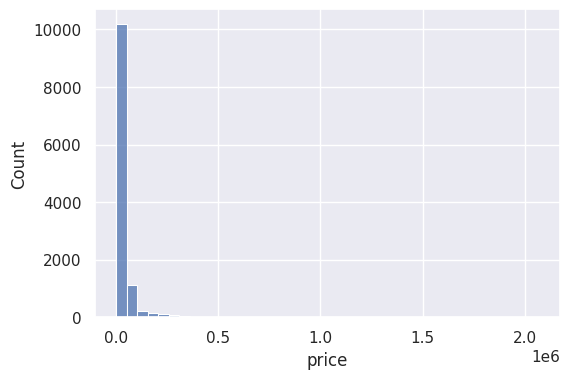

In [13]:
plt.figure(figsize=(6,4))
sns.histplot(df.price , bins=40)
plt.show()

In [14]:
df['price']= np.log1p(df.price) # نستعملها عشان نشيل bias data ويعطي تنوع

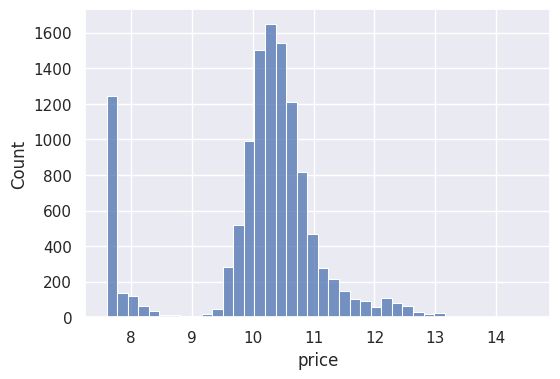

In [15]:
plt.figure(figsize=(6,4))
sns.histplot(df.price , bins=40)
plt.show()

part 3

In [16]:
print(df.isnull().sum())

make                    0
model                   0
year                    0
engine_fuel_type        3
engine_hp              69
engine_cylinders       30
transmission_type       0
driven_wheels           0
number_of_doors         6
market_category      3742
vehicle_size            0
vehicle_style           0
highway_mpg             0
city_mpg                0
popularity              0
price                   0
dtype: int64


In [17]:
df = df.drop(["market_category"], axis=1)

In [18]:
df['number_of_doors'] = df['number_of_doors'].fillna(df['number_of_doors'].mean())
df['engine_hp'] = df['engine_hp'].fillna(df['engine_hp'].mean())
df['engine_cylinders'] = df['engine_cylinders'].fillna(df['engine_cylinders'].mean())

In [19]:
df = df.drop(['engine_fuel_type'], axis=1)

In [20]:
print(df.isnull().sum())

make                 0
model                0
year                 0
engine_hp            0
engine_cylinders     0
transmission_type    0
driven_wheels        0
number_of_doors      0
vehicle_size         0
vehicle_style        0
highway_mpg          0
city_mpg             0
popularity           0
price                0
dtype: int64


In [21]:
df = df.drop(['transmission_type' , 'driven_wheels' , 'vehicle_style'] , axis=1)

part 4

In [22]:
df.head()

,make,model,year,engine_hp,engine_cylinders,number_of_doors,vehicle_size,highway_mpg,city_mpg,popularity,price
0,BMW,1 Series M,2011,335.0,6.0,2.0,Compact,26,19,3916,10.739349
1,BMW,1 Series,2011,300.0,6.0,2.0,Compact,28,19,3916,10.612779
2,BMW,1 Series,2011,300.0,6.0,2.0,Compact,28,20,3916,10.500977
3,BMW,1 Series,2011,230.0,6.0,2.0,Compact,28,18,3916,10.290483
4,BMW,1 Series,2011,230.0,6.0,2.0,Compact,28,18,3916,10.448744


In [23]:
# encoding الترميز

In [24]:
df= pd.get_dummies(df , columns=["make" , 'model' , 'vehicle_size'])

In [25]:
df.head()

,year,engine_hp,engine_cylinders,number_of_doors,highway_mpg,city_mpg,popularity,price,make_Acura,make_Alfa Romeo,...,model_iA,model_iM,model_iQ,model_tC,model_xA,model_xB,model_xD,vehicle_size_Compact,vehicle_size_Large,vehicle_size_Midsize
0,2011,335.0,6.0,2.0,26,19,3916,10.739349,False,False,...,False,False,False,False,False,False,False,True,False,False
1,2011,300.0,6.0,2.0,28,19,3916,10.612779,False,False,...,False,False,False,False,False,False,False,True,False,False
2,2011,300.0,6.0,2.0,28,20,3916,10.500977,False,False,...,False,False,False,False,False,False,False,True,False,False
3,2011,230.0,6.0,2.0,28,18,3916,10.290483,False,False,...,False,False,False,False,False,False,False,True,False,False
4,2011,230.0,6.0,2.0,28,18,3916,10.448744,False,False,...,False,False,False,False,False,False,False,True,False,False


In [26]:
x = df.drop(['price'] , axis=1)
y = df['price']

In [27]:
x

,year,engine_hp,engine_cylinders,number_of_doors,highway_mpg,city_mpg,popularity,make_Acura,make_Alfa Romeo,make_Aston Martin,...,model_iA,model_iM,model_iQ,model_tC,model_xA,model_xB,model_xD,vehicle_size_Compact,vehicle_size_Large,vehicle_size_Midsize
0,2011,335.0,6.0,2.0,26,19,3916,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,2011,300.0,6.0,2.0,28,19,3916,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,2011,300.0,6.0,2.0,28,20,3916,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,2011,230.0,6.0,2.0,28,18,3916,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,2011,230.0,6.0,2.0,28,18,3916,False,False,False,...,False,False,False,False,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11909,2012,300.0,6.0,4.0,23,16,204,True,False,False,...,False,False,False,False,False,False,False,False,False,True
11910,2012,300.0,6.0,4.0,23,16,204,True,False,False,...,False,False,False,False,False,False,False,False,False,True
11911,2012,300.0,6.0,4.0,23,16,204,True,False,False,...,False,False,False,False,False,False,False,False,False,True
11912,2013,300.0,6.0,4.0,23,16,204,True,False,False,...,False,False,False,False,False,False,False,False,False,True


In [28]:
y

,price
0,10.739349
1,10.612779
2,10.500977
3,10.290483
4,10.448744
...,...
11909,10.739024
11910,10.945018
11911,10.832122
11912,10.838031


part 5

In [29]:
from sklearn.model_selection import train_test_split

In [30]:
x_train , x_test , y_train , y_test = train_test_split(x , y , test_size=0.2 , random_state=42)

In [31]:
from sklearn.linear_model import LinearRegression

In [32]:
model = LinearRegression()
model.fit(x_train , y_train) # train level

LinearRegression()

In [33]:
from sklearn.metrics import mean_squared_error , r2_score

In [34]:
y_train_pred = model.predict(x_train)
mse = mean_squared_error(y_train , y_train_pred)
rmse = np.sqrt(mse) # rate of error
print(rmse)

0.1739977747156897


In [35]:
r2 = r2_score(y_train , y_train_pred) # accuracy of model
print(r2)

0.9750170447918122


part 6

In [36]:
from sklearn.tree import DecisionTreeRegressor

In [37]:
tree_model = DecisionTreeRegressor()
tree_model.fit(x_train , y_train) # train

DecisionTreeRegressor()

In [38]:
y_train_pred = tree_model.predict(x_train)
mse = mean_squared_error(y_train , y_train_pred)
rmse = np.sqrt(mse) # rate of error
print(rmse)

0.06149560925753141


In [39]:
r2 = r2_score(y_train , y_train_pred) # accuracy of model
print(r2)

0.9968793530486132


In [40]:
y_test_pred = tree_model.predict(x_test)
mse = mean_squared_error(y_test , y_test_pred)
rmse = np.sqrt(mse) # rate of error
print(rmse)

0.11100796410435805


In [41]:
r2_test = r2_score(y_test , y_test_pred) # accuracy of model
print(r2_test)

0.990254826209605


In [42]:
import joblib as jb
jb.dump(tree_model , "Ammar2_dt_model.pkl")

['Ammar2_dt_model.pkl']